# Seminar 2 · Part C · Problem 2: versicolor vs virginica

We fit **logistic regression** with two features, the petal length $x_1$ and the petal width $x_2$, to tell **versicolor** ($c = 0$) from **virginica** ($c = 1$), as in Part A. This problem is **not linearly separable**. Then we let the boundary bend with **polynomial features**, and meet **overfitting**.

**Plan of this notebook**

1. Load the data
2. Look at the data (EDA)
3. Logistic regression from scratch
4. Fit it with gradient ascent
5. The decision boundary
6. Evaluate it
7. Polynomial features: curved boundaries
8. Overfitting, on made-up data

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris     # the Iris dataset comes with scikit-learn

SEED = 1                                   # fixed random seed: everyone gets the same split and the same numbers
SPECIES = ["setosa", "versicolor", "virginica"]
FEATURES = ["petal length", "petal width"] # x1 and x2, in cm
COLORS = {"setosa": "#2e9e6b", "versicolor": "#2a78d6", "virginica": "#8e4fc0"}   # the slide colours

## 1. Load the data

The Iris dataset, as in Seminar 1: 150 flowers, numbered **1 to 150**. We keep only **versicolor** and **virginica** (flowers 51 to 150) and only the two petal measurements.

The label: $c^{(i)} = 0$ for versicolor, $c^{(i)} = 1$ for virginica.

In [2]:
iris = load_iris()
data = pd.DataFrame(iris.data[:, 2:4], columns=FEATURES)   # columns 2 and 3: petal length, petal width
data["species"] = [SPECIES[k] for k in iris.target]
data.index = range(1, len(data) + 1)                       # flower numbers 1, 2, ..., 150

data = data[data["species"].isin(["versicolor", "virginica"])].copy()
data["c"] = (data["species"] == "virginica").astype(int)   # the label: 1 for virginica, 0 for versicolor

X = data[FEATURES].to_numpy()      # one row per flower: (x1, x2)
c = data["c"].to_numpy()           # one label per flower
m = len(c)
print("m =", m, "flowers")
data.loc[[51, 101]]                # one flower of each species

m = 100 flowers


,petal length,petal width,species,c
51,4.7,1.4,versicolor,0
101,6.0,2.5,virginica,1


## 2. Look at the data (EDA)

In [3]:
print(data["species"].value_counts())
data.groupby("species")[FEATURES].agg(["min", "max"])

species
versicolor    50
virginica     50
Name: count, dtype: int64


petal length      petal width     
                    min  max         min  max
species                                      
versicolor          3.0  5.1         1.0  1.8
virginica           4.5  6.9         1.4  2.5

The ranges overlap: virginica petals can be shorter than some versicolor petals. Look at the picture.

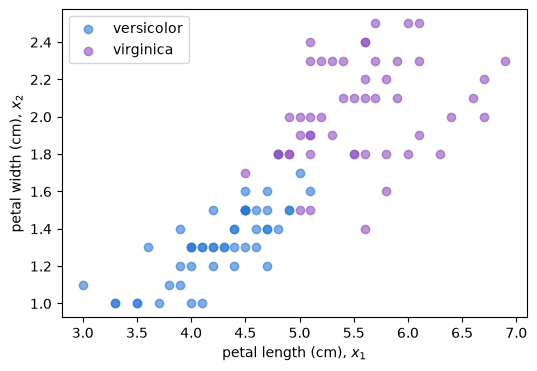

In [4]:
plt.figure(figsize=(6, 4))
for name in ["versicolor", "virginica"]:
    part = data[data["species"] == name]
    plt.scatter(part["petal length"], part["petal width"], color=COLORS[name], label=name, alpha=0.6)
plt.xlabel("petal length (cm), $x_1$")
plt.ylabel("petal width (cm), $x_2$")
plt.legend()
plt.show()

### Same measurements, different species

Some flowers have exactly the same two measurements. Are there two flowers with the **same features** but **different species**?

In [5]:
groups = data.groupby(FEATURES)["species"].agg(lambda s: sorted(set(s)))
both = groups[groups.apply(len) == 2]
print(both)
for (x1, x2) in both.index:
    same = data[(data["petal length"] == x1) & (data["petal width"] == x2)]
    print(same[["species"]].T)

petal length  petal width
4.8           1.8            [versicolor, virginica]
Name: species, dtype: object
                71         127        139
species  versicolor  virginica  virginica


Flower 71 (versicolor) and flowers 127 and 139 (virginica) all measure $x = (4.8, 1.8)$. **No classifier**, with a line or with any curve, can get all three right. That is why we model a **probability**.

## 3. Logistic regression from scratch

### The model and the log-likelihood (Parts A and B)

$$p_{\alpha,\beta}(x) = \operatorname{lgf}(\beta^T x + \alpha), \qquad \operatorname{lgf}(\ell) = \frac{1}{1 + e^{-\ell}},$$

$$\log \mathcal{L}(\alpha, \beta) = \sum_{i=1}^{m} \Big[c^{(i)} \log p_{\alpha,\beta}\big(x^{(i)}\big) + \big(1 - c^{(i)}\big) \log\Big(1 - p_{\alpha,\beta}\big(x^{(i)}\big)\Big)\Big].$$

### Gradient ascent (Part B)

Start at $\alpha^{(0)} = 0$, $\beta^{(0)} = 0$. In each step, add $\gamma$ times the gradient:

$$\frac{\partial \log \mathcal{L}}{\partial \alpha} = \sum_{i=1}^{m} \Big(c^{(i)} - p_{\alpha,\beta}\big(x^{(i)}\big)\Big), \qquad \frac{\partial \log \mathcal{L}}{\partial \beta_j} = \sum_{i=1}^{m} \Big(c^{(i)} - p_{\alpha,\beta}\big(x^{(i)}\big)\Big)\, x^{(i)}_j.$$

### The decision rule (Part A)

Predict $\hat{c} = 1$ when $\beta^T x + \alpha > 0$, and $\hat{c} = 0$ otherwise.

In [6]:
def lgf(l):
    """The logistic function: lgf(l) = 1 / (1 + e^(-l))."""
    return 1 / (1 + np.exp(-l))


def log_likelihood(alpha, beta, X, c):
    """log L(alpha, beta) for the items in the rows of X, with the labels c.
    We write  c log p + (1 - c) log(1 - p)  as  c * l - log(1 + e^l),  with l = beta^T x + alpha:
    the same number, but it never takes the log of 0."""
    l = X @ beta + alpha                            # the logit of every item
    return np.sum(c * l - np.logaddexp(0, l))       # np.logaddexp(0, l) = log(1 + e^l)


def gradient_ascent(X, c, gamma, steps, keep=()):
    """Gradient ascent on log L: start at 0, then `steps` steps of size gamma.
    Returns the last (alpha, beta), and a dictionary {t: (alpha_t, beta_t)} for the steps t in `keep`."""
    alpha, beta = 0.0, np.zeros(X.shape[1])         # alpha^(0) = 0, beta^(0) = (0, ..., 0)
    kept = {}
    for t in range(1, steps + 1):
        error = c - lgf(X @ beta + alpha)           # the error of each item: c^(i) - p(x^(i))
        alpha = alpha + gamma * np.sum(error)       # step for alpha: gamma * (sum of the errors)
        beta = beta + gamma * (error @ X)           # step for beta_j: gamma * (sum of error * x_j), for every j
        if t in keep:
            kept[t] = (alpha, beta.copy())
    return (alpha, beta), kept


def predict(alpha, beta, X):
    """The decision rule: 1 when beta^T x + alpha > 0, else 0. One prediction per row of X."""
    return (X @ beta + alpha > 0).astype(int)

## 4. Fit it with gradient ascent

On all 100 flowers. Learning rate $\gamma = 0.002$, **1,000,000 steps** (about 10–20 seconds). (With $\gamma = 0.003$, $\log \mathcal{L}$ goes down in some of the first steps: try it.)

In [7]:
GAMMA, STEPS = 0.002, 1_000_000

(alpha_hat, beta_hat), _ = gradient_ascent(X, c, GAMMA, STEPS)
print(f"alpha = {alpha_hat:.2f}   beta = ({beta_hat[0]:.2f}, {beta_hat[1]:.2f})   log L = {log_likelihood(alpha_hat, beta_hat, X, c):.3f}")

alpha = -45.27   beta = (5.75, 10.45)   log L = -10.282


### Compare with scikit-learn

scikit-learn has logistic regression ready to use: `LogisticRegression`. It is **the same model**,

$$P(\eta = 1 \mid \xi = x) = \operatorname{lgf}(\beta^T x + \alpha),$$

and it also finds $\hat{\alpha}, \hat{\beta}$ by maximizing $\log \mathcal{L}$, but with a faster iterative method than our gradient ascent (scikit-learn calls it `'lbfgs'`).

Using it takes **three steps: create, fit, read.**

**Step 1: create the model.** The arguments say how to fit it:

| Argument | Default | What it does | We use |
|---|---|---|---|
| `C` | `1.0` | Sets the strength of a penalty. `C=np.inf` means **no penalty**: then it maximizes exactly our $\log \mathcal{L}$. | `np.inf` |
| `tol` | `1e-4` | The method stops when the next iteration would change the result by less than this. | `1e-12`, for a precise maximum |
| `max_iter` | `100` | The largest number of iterations. | `100_000` |

One more argument we keep at its default: `fit_intercept=True`, the model has the intercept $\alpha$.

In [8]:
from sklearn.linear_model import LogisticRegression

sk_model = LogisticRegression(C=np.inf,           # no penalty: maximize log L, as we did
                              tol=1e-12,          # stop only when the changes are tiny
                              max_iter=100_000)   # allow many iterations

**Step 2: fit it** to the data: `X` has one row per flower and one column per feature, `c` has the labels (0 or 1). (`fit` returns the fitted model; Jupyter shows it with the arguments that are not at their defaults.)

In [10]:
sk_model.fit(X, c)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",inf
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",1e-12
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",100000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

**Step 3: read the parameters.**

- `intercept_` is an array with **1** number: $\hat{\alpha}$ = `intercept_[0]`.
- `coef_` is an array of shape $(1, d)$, **one row**: $\hat{\beta}$ = `coef_[0]`.

(The arrays have this shape because the same class also handles more than two classes, with one row per class.)

In [11]:
print("intercept_ :", sk_model.intercept_, "  shape", sk_model.intercept_.shape)
print("coef_      :", sk_model.coef_, "  shape", sk_model.coef_.shape)

alpha_sk = sk_model.intercept_[0]     # alpha hat
beta_sk = sk_model.coef_[0]           # beta hat = (beta_1, beta_2)

intercept_ : [-45.27234382]   shape (1,)
coef_      : [[ 5.75453233 10.44669989]]   shape (1, 2)


**Using it: `predict` and `predict_proba`.**

- `predict(X)` gives the predicted class of every row of `X`, with the decision rule (Part A).
- `predict_proba(X)` gives, for every row, the probabilities of class 0 and class 1: column 1 is $p_{\hat\alpha,\hat\beta}(x)$.

The first three flowers:

In [12]:
print("predicted class:", sk_model.predict(X[:3]))
print("probabilities (class 0, class 1):")
print(sk_model.predict_proba(X[:3]).round(3))

predicted class: [0 0 0]
probabilities (class 0, class 1):
[[0.973 0.027]
 [0.976 0.024]
 [0.803 0.197]]


**The comparison.** Our gradient ascent and scikit-learn reach the same maximum.

Read more: the [documentation of `LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

In [13]:
print(f"gradient ascent: alpha = {alpha_hat:.2f}   beta = ({beta_hat[0]:.2f}, {beta_hat[1]:.2f})   "
      f"log L = {log_likelihood(alpha_hat, beta_hat, X, c):.3f}")
print(f"scikit-learn:    alpha = {alpha_sk:.2f}   beta = ({beta_sk[0]:.2f}, {beta_sk[1]:.2f})   "
      f"log L = {log_likelihood(alpha_sk, beta_sk, X, c):.3f}")

gradient ascent: alpha = -45.27   beta = (5.75, 10.45)   log L = -10.282
scikit-learn:    alpha = -45.27   beta = (5.75, 10.45)   log L = -10.282


## 5. The decision boundary

The **decision boundary** is the line $\beta^T x + \alpha = 0$. Two ways to draw it:

1. solve for the petal width: $x_2 = -(\beta_1 x_1 + \alpha) / \beta_2$;
2. draw the **contour line** $p_{\alpha,\beta}(x) = 0.5$.

We draw it the second way, together with the contour lines $p = 0.1, 0.25, 0.75, 0.9$. We circle the flowers on the wrong side.

In [14]:
p = lgf(X @ beta_hat + alpha_hat)                      # the model's probability of virginica, for every flower
wrong = predict(alpha_hat, beta_hat, X) != c
print(f"line: x2 = {-alpha_hat / beta_hat[1]:.2f} - {beta_hat[0] / beta_hat[1]:.3f} x1")
print("on the wrong side:", wrong.sum(), "of", m)
data.assign(p=p.round(2))[wrong]

line: x2 = 4.33 - 0.551 x1
on the wrong side: 6 of 100


,petal length,petal width,species,c,p
71,4.8,1.8,versicolor,0,0.76
78,5.0,1.7,versicolor,0,0.78
84,5.1,1.6,versicolor,0,0.69
107,4.5,1.7,virginica,1,0.17
120,5.0,1.5,virginica,1,0.30
134,5.1,1.5,virginica,1,0.44


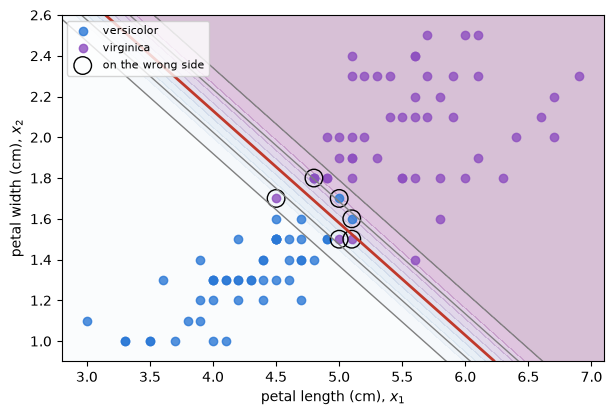

In [15]:
H1, H2 = np.meshgrid(np.linspace(2.8, 7.1, 200), np.linspace(0.9, 2.6, 200))   # a grid of points (x1, x2)
grid = np.column_stack([H1.ravel(), H2.ravel()])
P = lgf(grid @ beta_hat + alpha_hat).reshape(H1.shape)                       # p at every point of the grid

plt.figure(figsize=(7, 4.5))
plt.contourf(H1, H2, P, levels=np.linspace(0, 1, 11), cmap="BuPu", alpha=0.25)
plt.contour(H1, H2, P, levels=[0.1, 0.25, 0.75, 0.9], colors="gray", linewidths=1)
plt.contour(H1, H2, P, levels=[0.5], colors="#c0392b", linewidths=2)
for name in ["versicolor", "virginica"]:
    part = data[data["species"] == name]
    plt.scatter(part["petal length"], part["petal width"], color=COLORS[name], label=name, alpha=0.8)
plt.scatter(X[wrong, 0], X[wrong, 1], s=160, facecolors="none", edgecolors="black", label="on the wrong side")
plt.xlabel("petal length (cm), $x_1$")
plt.ylabel("petal width (cm), $x_2$")
plt.legend(fontsize=8)
plt.show()

The contour lines are **parallel lines**. 6 flowers are on the wrong side: Problem 2 is **not linearly separable**.

## 6. Evaluate it

As in Seminar 1: a random **training set** (80% of the flowers) and a **test set** (the other 20%). We fit on the training set only.

The **training error** is the fraction of the training items misclassified; the **test error** is the fraction of the test items misclassified, $1 -$ accuracy.

Training set: 80 flowers;  Test set: 20 flowers
training error: 0.0625
test error:     0.05


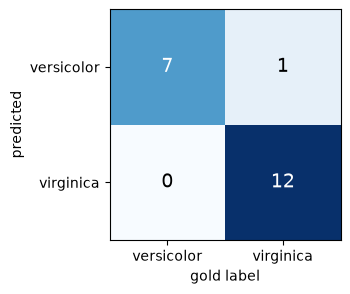

In [16]:
rng = np.random.default_rng(SEED)
order = rng.permutation(m)                 # the flowers in a random order
n_train = int(0.8 * m)
train, test = order[:n_train], order[n_train:]
print("Training set:", len(train), "flowers;  Test set:", len(test), "flowers")

(alpha_train, beta_train), _ = gradient_ascent(X[train], c[train], GAMMA, STEPS)
predicted = predict(alpha_train, beta_train, X[test])

print("training error:", np.mean(predict(alpha_train, beta_train, X[train]) != c[train]))
print("test error:    ", np.mean(predicted != c[test]))
confusion = pd.crosstab(pd.Series(predicted, name="predicted"), pd.Series(c[test], name="gold label"))

# The confusion matrix as a picture: rows = predicted class, columns = gold label (as in Seminar 1)
confusion = confusion.reindex(index=[0, 1], columns=[0, 1], fill_value=0)   # keep both rows and columns, even if a count is 0
fig, ax = plt.subplots(figsize=(3.5, 3))
ax.imshow(confusion, cmap="Blues")                 # darker blue = more flowers
for row in range(2):
    for col in range(2):
        count = confusion.iloc[row, col]
        color = "white" if count > confusion.to_numpy().max() / 2 else "black"   # white text on dark squares
        ax.text(col, row, count, ha="center", va="center", fontsize=14, color=color)
names = ["versicolor", "virginica"]   # label 0, label 1
ax.set_xticks([0, 1], names)
ax.set_yticks([0, 1], names)
ax.set_xlabel("gold label")
ax.set_ylabel("predicted")
plt.show()

## 7. Polynomial features: curved boundaries

The **polynomial features** of degree $K$: $\phi(x)$ = all products $x_1^{k_1} x_2^{k_2}$ with $1 \le k_1 + k_2 \le K$. The model is

$$P(\eta = 1 \mid \xi = x) = \operatorname{lgf}\big(\beta^T \phi(x) + \alpha\big),$$

with one entry of $\beta$ per entry of $\phi(x)$. It is still logistic regression, linear in $\alpha$ and $\beta$: the same likelihood, with $\phi(x^{(i)})$ in place of $x^{(i)}$. The boundary $\beta^T \phi(x) + \alpha = 0$ is a **curve**.

scikit-learn makes $\phi(x)$ for us: `PolynomialFeatures`. For $K = 2$ and flower 51:

In [17]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.exceptions import ConvergenceWarning

x1, x2 = data.loc[51, FEATURES]
print("flower 51: x =", (x1, x2))
print("by hand:   phi(x) =", np.round([x1, x2, x1**2, x1 * x2, x2**2], 2).tolist())

poly = PolynomialFeatures(2, include_bias=False)        # include_bias=False: no constant 1 (we have alpha)
print("scikit-learn:      ", poly.fit_transform([[x1, x2]])[0].round(2).tolist())
print("names:", poly.get_feature_names_out(["x1", "x2"]).tolist())

flower 51: x = (4.7, 1.4)
by hand:   phi(x) = [4.7, 1.4, 22.09, 6.58, 1.96]
scikit-learn:       [4.7, 1.4, 22.09, 6.58, 1.96]
names: ['x1', 'x2', 'x1^2', 'x1 x2', 'x2^2']


### Fitting with polynomial features

With many features, plain gradient ascent needs very many steps, so here we let scikit-learn do the fitting, still **without a penalty** (`C=np.inf`).

One more step: `StandardScaler` rescales each feature to mean 0 and standard deviation 1. This helps the fitting method a lot; without a penalty it does not change the boundary.

With many features the training items can become separable; then scikit-learn warns that it did not converge. We expect this, so we hide that warning.

K =  1:  2 features in phi(x);  training error = 6 of 100
K =  2:  5 features in phi(x);  training error = 3 of 100
K =  4: 14 features in phi(x);  training error = 1 of 100
K = 10: 65 features in phi(x);  training error = 1 of 100


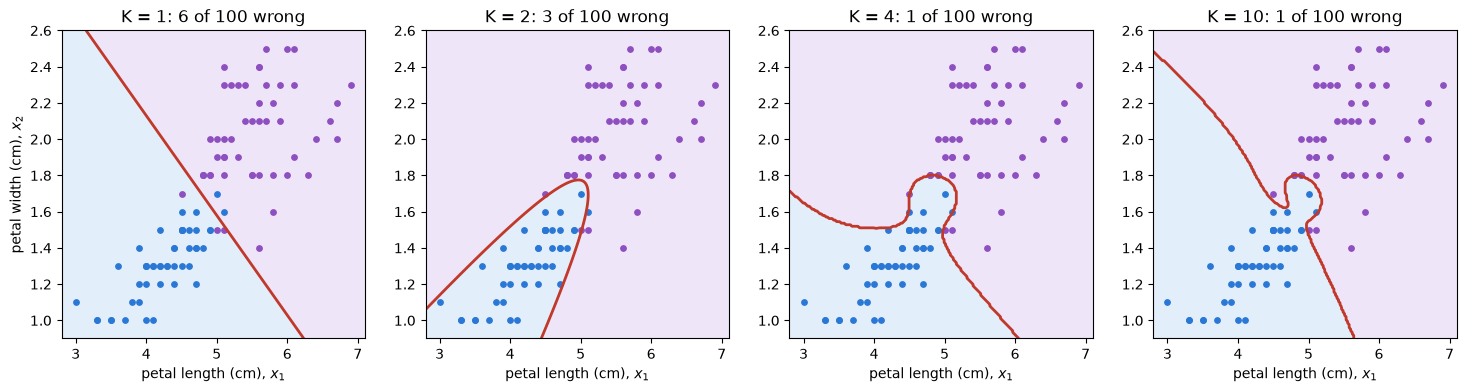

In [18]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)


def fit_polynomial(K, X, c):
    """Logistic regression on the polynomial features of degree K, without a penalty."""
    return make_pipeline(PolynomialFeatures(K, include_bias=False), StandardScaler(),
                         LogisticRegression(C=np.inf, tol=1e-10, max_iter=100_000)).fit(X, c)


fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, K in zip(axes, [1, 2, 4, 10]):
    model = fit_polynomial(K, X, c)                                   # fitted on all 100 flowers
    n_wrong = np.sum(model.predict(X) != c)
    print(f"K = {K:>2}: {model[0].n_output_features_:>2} features in phi(x);  training error = {n_wrong} of {m}")
    P = model.predict_proba(grid)[:, 1].reshape(H1.shape)            # p at every point of the grid
    ax.contourf(H1, H2, P, levels=[0, 0.5, 1], colors=["#e3eefb", "#efe5f8"])
    ax.contour(H1, H2, P, levels=[0.5], colors="#c0392b", linewidths=2)
    for name in ["versicolor", "virginica"]:
        part = data[data["species"] == name]
        ax.scatter(part["petal length"], part["petal width"], color=COLORS[name], s=15)
    ax.set_title(f"K = {K}: {n_wrong} of {m} wrong")
    ax.set_xlabel("petal length (cm), $x_1$")
axes[0].set_ylabel("petal width (cm), $x_2$")
plt.show()

The training error goes down: 6, 3, 1, 1 of 100. Never 0, because of flowers 71, 127, 139. The $K = 10$ curve bends around single flowers.

**Is it better for new flowers?** With 100 flowers, a test set has 20 flowers, and one flower is already 5%: too few to tell. So we make up data, where we can make as many new items as we like.

## 8. Overfitting, on made-up data

Each item: the label $\eta = 0$ or $1$, with probability $1/2$ each. Given $\eta = 0$, the two features $\xi_1, \xi_2$ are independent $\mathcal{N}(0, 1)$; given $\eta = 1$, they are independent $\mathcal{N}(0, 2^2)$. Class 1 is more spread out, so the best boundary is a circle: $K = 2$ is the right degree.

**40** training items, and **5,000** test items.

In [19]:
def make_data(rng, n):
    """n made-up items: labels 0 or 1 (probability 1/2 each); features N(0, 1) for class 0, N(0, 2^2) for class 1."""
    labels = rng.integers(0, 2, n)
    sd = np.where(labels == 1, 2.0, 1.0)[:, None]          # the standard deviation of each item
    return rng.normal(0, 1, (n, 2)) * sd, labels


rng = np.random.default_rng(0)
X_train, c_train = make_data(rng, 40)       # the training set
X_test, c_test = make_data(rng, 5000)       # the test set: new items, never used for fitting

DEGREES = range(1, 11)
train_error, test_error, models = [], [], {}
for K in DEGREES:
    models[K] = fit_polynomial(K, X_train, c_train)
    train_error.append(np.mean(models[K].predict(X_train) != c_train))
    test_error.append(np.mean(models[K].predict(X_test) != c_test))
    print(f"K = {K:>2}:  training error = {train_error[-1]:.3f}   test error = {test_error[-1]:.3f}")

K =  1:  training error = 0.300   test error = 0.498
K =  2:  training error = 0.250   test error = 0.275
K =  3:  training error = 0.225   test error = 0.339
K =  4:  training error = 0.000   test error = 0.352
K =  5:  training error = 0.000   test error = 0.366
K =  6:  training error = 0.000   test error = 0.393
K =  7:  training error = 0.000   test error = 0.383
K =  8:  training error = 0.000   test error = 0.396
K =  9:  training error = 0.000   test error = 0.391
K = 10:  training error = 0.000   test error = 0.384


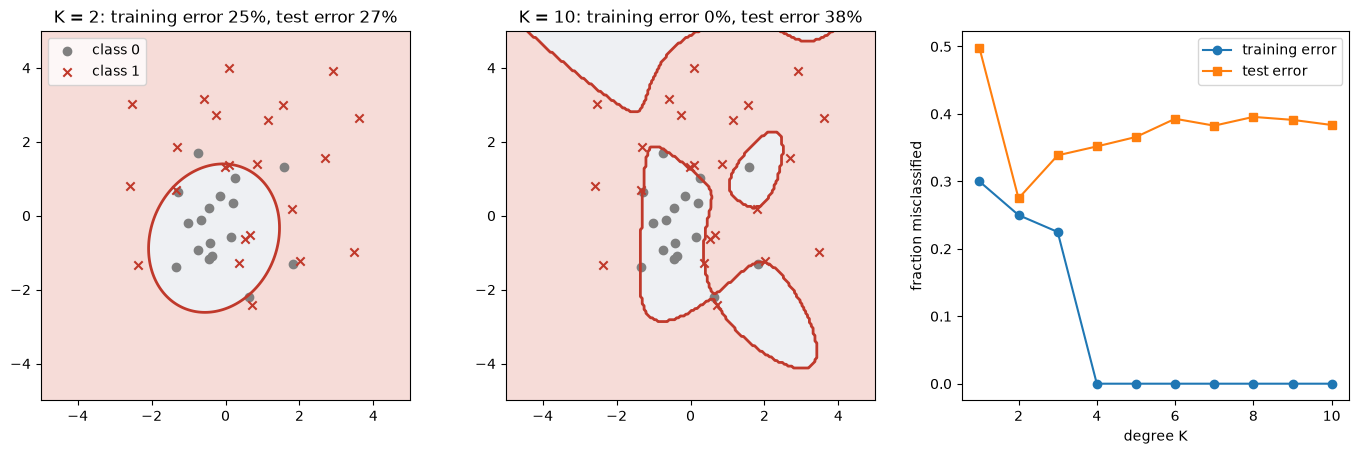

In [20]:
S1, S2 = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-5, 5, 200))
grid_s = np.column_stack([S1.ravel(), S2.ravel()])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, K in zip(axes[:2], [2, 10]):
    P = models[K].predict_proba(grid_s)[:, 1].reshape(S1.shape)
    ax.contourf(S1, S2, P, levels=[0, 0.5, 1], colors=["#eef0f3", "#f6dcd8"])
    ax.contour(S1, S2, P, levels=[0.5], colors="#c0392b", linewidths=2)
    ax.scatter(X_train[c_train == 0, 0], X_train[c_train == 0, 1], color="gray", label="class 0")
    ax.scatter(X_train[c_train == 1, 0], X_train[c_train == 1, 1], color="#c0392b", marker="x", label="class 1")
    ax.set_aspect("equal")
    ax.set_title(f"K = {K}: training error {train_error[K - 1]:.0%}, test error {test_error[K - 1]:.0%}")
axes[0].legend()
axes[2].plot(DEGREES, train_error, "o-", label="training error")
axes[2].plot(DEGREES, test_error, "s-", label="test error")
axes[2].set_xlabel("degree K")
axes[2].set_ylabel("fraction misclassified")
axes[2].legend()
plt.show()

- The **training error** goes down as $K$ grows, to 0 from $K = 4$ on (then the training items are separable, as in Problem 1).
- The **test error** is lowest at $K = 2$, the right degree, and then goes **up**.

This is **overfitting**: a model that fits the training data very well but is too complex has a low training error but a higher test error.

**Your turn (the challenge of the slides):** change 40 to 400 in `make_data(rng, 40)` and run the last two cells again. What happens to the gap between the two curves?

## Summary

- Problem 2 is **not linearly separable**: the fitted line gets 6 of 100 flowers wrong, and three flowers with the same features have different species.
- Gradient ascent reaches the maximum of the likelihood, the same as scikit-learn.
- **Polynomial features** $\phi(x)$ make the boundary a curve; the model is still logistic regression.
- A higher degree lowers the **training error**, but too high a degree raises the **test error**: **overfitting**.